# v8：三鱼状态，主角配对用 B 的分辨率 — 离散（T8）与不离散（G8）两个版本

**目的**：v7 的三鱼状态（T7）在 K、P 上不如配对状态 B，原因之一是 T7 里主角配对的分档比 B 粗（距离 4 档 vs 7 档、主角朝向 4 vs 8、高度差 3 vs 4、速度 2 vs 3）。v8 让三鱼状态**包含 B 的全部信息**：
- **T8（离散）**：主角配对 = B 的 v3b 6 变量微状态（原分辨率，含 contact 状态）；另一条雄鱼、雄–雄关系用 v7 的粗分档加在上面。分层回退的最后一级就是 B（qc）/ B+seq（攻击），所以数据不够时退回 B，而不是退回更粗的配对。
- **G8（不离散）**：同一批变量全部用连续值，交给梯度提升树（`sklearn` 的 `HistGradientBoostingClassifier`）。切点由训练数据学出来，不需要人定分档，也没有状态数爆炸的问题。

**轮流主角不变**：每帧两行（主角 = M1 / M2），两条雄鱼对称；"细"和"粗"是角色（主角 / 另一条）的差别，不是个体的差别——每条雄鱼都在自己当主角的那一行里得到 B 的分辨率。

**设定（与 v7 / v7b 相同的部分）**：训练 K_1_1、K_1_2、P_1_1、P_1_2；测试 K_1_3、P_1_3、E_1_1、E_1_2、E_1_3；没有 BORIS 标注 = 没有该行为，Chase 等其他行为 = 不评估；阈值用训练集交叉预测（留一录像）分数选；相同误报率（0.25 / 0.5 / 1 次 / 配对·分钟）下比较检出 bout 数。回转角窗口固定 0.5 s、攻击时间顺序窗口固定 0.1 s（v7 / v7b 在训练集上选出的值）。

**和 v7 的区别**：
- **标注**：K_1_2 中 6 个求爱 bout 和 1 次抱接在 BORIS 里雄鱼记反，已修正（2026-11-10，用户看视频确认）。所以本 notebook 里 B、B+rot、T7+rot 的 qc 结果和 v7 略有不同；攻击标注没有变化。
- **不做 Infomap（C）**：在三鱼状态上它分成上万个小簇，v7 中最差。
- **新增 B+seq**（攻击）：v7b 只测了 T+seq，没法区分提升来自三鱼还是来自时间顺序变量。
- **bout 计数**（2026-11-10 修改）：一个 BORIS bout 中间有被排除的帧（审核不可用 / 坐标缺失）时，按一个 bout 计（v7 会把它数成两个）；只看它的可用帧，可用帧中至少一半被检出才算找到；完全落在排除帧上的 bout 不计入。

**方法**（每个目标都用同一批帧、同一套打分 → 平滑 → 阈值流程）：

| 目标 | 名称 | 内容 |
|---|---|---|
| qc | B | v3b 配对微状态（F–主角），基准 |
| qc | B+rot | B + 主角累积回转角 |
| qc | T7+rot | v7 的 T+rot（三鱼，主角配对粗分档），参照 |
| qc | **T8+rot** | B × rot × 另一条雄鱼（粗）× 雄–雄（粗），回退到 B+rot、B |
| qc | **G8+rot** | 与 T8+rot 同一批变量的连续值 → 梯度提升树 |
| att | B | v3b 配对微状态（主角–另一条），基准 |
| att | B+seq | B + 攻击时间顺序变量 6 个 |
| att | T7+seq | v7b 的 T+seq，参照 |
| att | **T8+seq** | B × 时间顺序变量 × 雌鱼相对两条雄鱼的位置（粗）+ 雌鱼速度，回退到 B+seq、B |
| att | **G8+seq** | 与 T8+seq 同一批变量的连续值 → 梯度提升树 |

## 参数

数据划分、BORIS 类别、粗分档、回退顺序、方法定义、梯度提升树设置和评估设置都在这里。分档单位：距离 mm、速度 mm/s、角度在 `scripts/analysis/trio_state.bin_values` 里按 45° / 90° 分。所有分档都多一个"未定义"档。

In [1]:
# ============================== Parameters ==============================
from pathlib import Path

RUN_NAME = "20261110_trio_focalB_v8"
SOURCE_RUN = "20261108_pair_state6d_clean_sw11_v3b"   # read: params.json (cleaning) and the 6-variable bin edges (B)
OUTPUT_ROOT = None       # None -> <runs_dir>/behavior_features/outputs (paths config)
TRAIN_EXPERIMENTS = ["20251225_K_1_1_FCMC", "20251225_K_1_2_FCMC", "20260112_P_1_1_FCMC", "20260113_P_1_2_FCMC"]
TEST_EXPERIMENTS = ["20251225_K_1_3_FCMC", "20260112_P_1_3_FCMC", "20251220_E_1_1_FCMC", "20251220_E_1_2_FCMC", "20251220_E_1_3_FCMC"]
REVIEW_MIN_WATCHED_PCT = 99.0    # a recording is used only if its ID-pass summary says at least this much was watched
TARGETS = ["qc", "att"]
DPI = 200
THUMB_WIDTH = 900

LABEL_CLASSES = {"wrap": ["wrap"], "qc": ["quick circle", "incomplete qc", "courtship"],
                 "att": ["attack", "attempted att", "dash"]}
COPIES = [("M1", "M2"), ("M2", "M1")]   # (focal, rival): every frame twice, each male focal once
EVAL_COPIES = {"qc": [0, 1], "att": [0]}  # att labels are symmetric -> one copy per frame, as v6 (M1M2)

# --- coarse three-fish bins (as v7)
D_EDGES = [0, 10, 20, 40, float("inf")]
DZ_EDGES = [-float("inf"), -20, 20, float("inf")]
SP_EDGES = [0, 60, float("inf")]
MD_EDGES = [0, 15, 40, float("inf")]
TRIO_SPECS = {
    "fD": ("lin", D_EDGES), "fdz": ("lin", DZ_EDGES), "fthF": ("half4", None), "fthM": ("circ4", None), "fsp": ("lin", SP_EDGES),
    "rD": ("lin", D_EDGES), "rdz": ("lin", DZ_EDGES), "rthF": ("circ4", None), "rthM": ("circ4", None), "rsp": ("lin", SP_EDGES),
    "Fsp": ("lin", SP_EDGES), "mD": ("lin", MD_EDGES), "mthf": ("circ4", None), "mthr": ("circ4", None),
}
ROT_WINDOW_S = 0.5                     # fixed: chosen on train in v7 (LOEO AP of B+rot among 0.5 / 1 / 2 s)
ROT_EDGES = [0, 45, 90, float("inf")]  # degrees

# --- attack time-order variables (as v7b)
SEQ_SMOOTH_WINDOW = 5                  # SG window for these variables only (frames)
SEQ_WINDOW_S = 0.1                     # fixed: chosen on train in v7b (LOEO AP of T+seq among 0.05 / 0.1 / 0.2 s)
SEQ_SPECS = {
    "lead": ("lin", [-float("inf"), 100, 300, float("inf")]),          # focal peak approach speed toward the rival (mm/s)
    "who": ("lin", [-float("inf"), -100, 100, float("inf")]),          # focal peak - rival peak approach speed (mm/s)
    "dmin": ("lin", [0, 5, 15, float("inf")]),                          # minimum 3D distance in the window (mm)
    "tmin": ("lin", [-float("inf"), -1 / 3, 1 / 3, float("inf")]),     # time of the minimum / half-window (-1 = start, +1 = end)
    "turn": ("lin", [0, 30, 90, float("inf")]),                         # rival heading change after the minimum (deg)
    "dsp": ("lin", [-float("inf"), 50, 150, float("inf")]),            # rival speed increase after the minimum (mm/s)
}
SEQ = list(SEQ_SPECS)
SEQ4 = ["lead", "who", "dmin", "turn"]
SEQ2 = ["who", "dmin"]

# --- back-off levels (finest first). "B" = the v3b 6-variable state of the target's pair.
FOC = ["fD", "fdz", "fthF", "fthM", "fsp"]
RIV = ["rD", "rdz", "rthF", "rthM", "rsp"]
MMV = ["mD", "mthf", "mthr"]
LEVELS = {
    "qc": {
        "B": [["B"]],
        "B+rot": [["B", "rot"], ["B"]],
        # v7 T+rot
        "T7+rot": [FOC + RIV + ["Fsp"] + MMV + ["rot"], FOC + RIV + ["Fsp", "mD", "rot"],
                   FOC + ["rD", "rdz", "rthF", "Fsp", "mD", "rot"], FOC + ["rD", "Fsp", "mD", "rot"], FOC + ["rot"]],
        # B at full resolution; drop M-M angles and rival heading first, then rival height/speed, then direction
        "T8+rot": [["B", "rot"] + RIV + MMV, ["B", "rot", "rD", "rdz", "rthF", "rsp", "mD"],
                   ["B", "rot", "rD", "rthF", "mD"], ["B", "rot", "rD"], ["B", "rot"], ["B"]],
    },
    "att": {
        "B": [["B"]],
        "B+seq": [["B"] + SEQ, ["B"] + SEQ4, ["B"] + SEQ2, ["B"]],
        # v7b T+seq
        "T7+seq": [FOC + RIV + ["Fsp"] + MMV + SEQ, FOC + RIV + MMV + SEQ,
                   ["fD", "fdz", "fthM", "fsp", "rD", "rdz", "rthM", "rsp"] + MMV + SEQ,
                   ["fD", "fsp", "rD", "rsp"] + MMV + SEQ, ["fsp", "rsp"] + MMV + SEQ,
                   ["mD", "fsp", "rsp"] + SEQ4, ["mD", "fsp", "rsp"] + SEQ2, ["mD", "fsp", "rsp"]],
        # B (pair focal-rival) at full resolution + where the female is (coarse) + her speed
        "T8+seq": [["B"] + SEQ + ["fD", "rD", "Fsp"], ["B"] + SEQ + ["fD", "rD"], ["B"] + SEQ,
                   ["B"] + SEQ4, ["B"] + SEQ2, ["B"]],
    },
}

# --- continuous version (G8): the same variables as T8, as continuous values
ANGLES = ["fthF", "fthM", "rthF", "rthM", "mthf", "mthr"]   # angles get an extra cos() column
G_FEATURES = {
    "qc": ["fD", "fdz", "fthF", "fthM", "fsp", "Fsp", "rot"] + RIV + MMV,
    "att": ["mDxy", "mdz", "mthf", "mthr", "fsp", "rsp"] + SEQ + ["fD", "rD", "Fsp"],
}
G_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                early_stopping=False, random_state=0)
G_CLASS_WEIGHTS = [None, "balanced"]    # chosen per target by LOEO AP on train
IMPORTANCE_NEG_SAMPLE = 300_000          # test rows (all positives + this many negatives) for permutation importance
IMPORTANCE_REPEATS = 3
PDP_SAMPLE = 20_000
PDP_TOP = 6

METHODS = {
    "qc": {"B": "discrete", "B+rot": "discrete", "T7+rot": "discrete", "T8+rot": "discrete", "G8+rot": "continuous"},
    "att": {"B": "discrete", "B+seq": "discrete", "T7+seq": "discrete", "T8+seq": "discrete", "G8+seq": "continuous"},
}
SMOOTH = {"qc": 124, "att": 5}          # centred smoothing of the frame scores (frames), as v3b / v6 / v7
PRIOR_FRAMES = 50.0
FA_TARGETS = [0.25, 0.5, 1.0]           # false alarms / pair-min fixed on train for the matched comparison

PARAMETERS = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()
              if k.isupper() and k != "PARAMETERS"}
print(f"{len(PARAMETERS)} parameters; run {RUN_NAME}; targets {TARGETS}")

41 parameters; run 20261110_trio_focalB_v8; targets ['qc', 'att']


## Setup（公共函数，不是分析步骤）

找仓库根目录、读路径配置、建输出目录，读 v3b 的清洗参数和 6 变量分格边界，检查每个录像的 ID-pass 是否完成。计算逻辑在 `scripts/analysis/trio_state.py`（单元测试 `tests/test_trio_state.py`）。

In [2]:
import os
import sys
import time
import json
import platform
import warnings

REPO = Path.cwd().resolve()
while not (REPO / "pyproject.toml").exists():
    if REPO.parent == REPO:
        raise RuntimeError("repository root (pyproject.toml) not found above the working directory")
    REPO = REPO.parent
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPImage, display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve

from scripts.analysis import microstate as M
from scripts.analysis import pose_states as S
from scripts.analysis import pair_state4d as P4
from scripts.analysis import trio_state as TS
from scripts.analysis.behavior_dataset import find_package, resolve_roots

_CONFIG, REVIEW_ROOT, _BF_ROOT = resolve_roots(None)
OUT_ROOT = Path(OUTPUT_ROOT) if OUTPUT_ROOT else Path(_BF_ROOT) / "outputs"
L = S.RunLayout(OUT_ROOT / RUN_NAME, dpi=DPI, thumb_width=THUMB_WIDTH)
SRC = OUT_ROOT / SOURCE_RUN
V3B = json.loads((SRC / "params.json").read_text())["parameters"]
_edge_files = sorted((SRC / "data").glob("02_bin_edges__all__*__train.json"))
assert len(_edge_files) == 1, _edge_files
EDGES_JSON = json.loads(_edge_files[0].read_text())
EDGES = [np.asarray(x, dtype=np.float64) for x in EDGES_JSON["edges"]]
CONTACT_ID = int(EDGES_JSON["contact_state"])
N_B_STATES = int(EDGES_JSON["n_states"])
METHOD_COLOR = {"B": "#9e9e9e", "B+rot": "#4C78A8", "B+seq": "#4C78A8", "T7+rot": "#54A24B", "T7+seq": "#54A24B",
                "T8+rot": "#B279A2", "T8+seq": "#B279A2", "G8+rot": "#E45756", "G8+seq": "#E45756"}


def _allow_listed(experiment, final):
    if experiment not in TRAIN_EXPERIMENTS + TEST_EXPERIMENTS:
        raise PermissionError(f"{experiment} is not in TRAIN_EXPERIMENTS / TEST_EXPERIMENTS")


M.require_access = _allow_listed


def exp_short(e):
    g, t = M.parse_experiment(e)
    return f"{g}_{t}"


def show(p):
    display(IPImage(filename=str(L.thumbs / p.name)))


def review_status(e):
    # (usable?, reason) from the ID-pass summary of the experiment's review package
    try:
        pkg = find_package(REVIEW_ROOT, e)
    except BaseException as ex:   # find_package raises SystemExit
        return False, f"no ID-pass package ({ex})"
    p = Path(pkg) / "id_pass" / "id_pass_summary.json"
    if not p.exists():
        return False, "ID-pass not finished (no id_pass_summary.json)"
    s = json.loads(p.read_text(encoding="utf-8"))
    w = float(s.get("watched_pct", 0.0))
    return w >= REVIEW_MIN_WATCHED_PCT, f"watched {w:.1f}%, usable {s.get('usable_pct')}%"


SKIPPED = {}
for e in list(TEST_EXPERIMENTS):
    ok, why = review_status(e)
    if not ok:
        SKIPPED[e] = why
        TEST_EXPERIMENTS.remove(e)
for e in TRAIN_EXPERIMENTS:
    ok, why = review_status(e)
    assert ok, f"training experiment {e}: {why}"
print("train:", [exp_short(e) for e in TRAIN_EXPERIMENTS])
print("test: ", [exp_short(e) for e in TEST_EXPERIMENTS])
print("skipped:", SKIPPED or "none")
L.update_params("parameters", PARAMETERS)
L.update_params("run", {"run_name": RUN_NAME, "date": time.strftime("%Y-%m-%d %H:%M:%S"), "output_dir": str(L.root),
                        "source_dir": str(SRC), "platform": platform.platform(),
                        "test_used": TEST_EXPERIMENTS, "test_skipped": SKIPPED})
print("output folder", L.root)

train: ['K_1_1', 'K_1_2', 'P_1_1', 'P_1_2']
test:  ['K_1_3', 'P_1_3', 'E_1_1', 'E_1_2', 'E_1_3']
skipped: none
output folder \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261110_trio_focalB_v8


## Step 0 — 预处理：每个录像、每个副本（主角 = M1 / M2）的变量

与 v7 相同：
1. 读审核后的 3D 坐标（`load_trial(final=True)`），按 v3b 清洗：去异常骨架 → ≤ 5 帧插值（不跨审核屏蔽帧）→ SG 11 帧平滑；胸鳍速度同 v3b。
2. 每个副本 (F, 主角, 另一条)：`trio_variables` → 镜像（主角放到雌鱼的同一侧）；主角累积回转角（0.5 s）；B 用的 v3b 6 变量微状态（qc：F–主角；攻击：主角–另一条，含 contact 状态）。
3. 新增（G8 攻击用）：主角–另一条的水平距离 `mDxy` 和高度差 `mdz`（= B 攻击配对的前两个变量的连续值）。
4. 标签：qc = F–主角的 BORIS qc；att = 主角–另一条的 BORIS att。审核不可用的帧、三鱼的距离 / 速度不全的帧 → 不参与评估（-1）。BORIS 文件是修正后的版本（K_1_2）。

T8 里 B 的状态没有镜像（和 v3b 完全一样），另一条雄鱼的角度沿用镜像后的值。因为 B 本身记录了主角在雌鱼哪一侧，这两种写法携带的信息相同。

In [3]:
# Step 0: per experiment and copy, the three-fish variables, rotation, v3b pair states and labels.
FISH_IX = {f: i for i, f in enumerate(P4.FISH)}


def clean_nodes(tr, window):
    nodes = np.array(tr["named"], dtype=np.float64, copy=True)
    blocked = np.asarray(tr["blocked"], dtype=bool)
    hp = np.linalg.norm(nodes[:, :, P4.HEAD] - nodes[:, :, P4.PEC], axis=-1)
    pt = np.linalg.norm(nodes[:, :, P4.PEC] - nodes[:, :, P4.TAIL], axis=-1)
    bad = (np.isfinite(hp) & (hp > V3B["HEAD_PEC_MAX_MM"])) | (np.isfinite(pt) & (pt > V3B["PEC_TAIL_MAX_MM"]))
    nodes[bad] = np.nan
    nodes = M.fill_gaps(nodes, V3B["FILL_LIMIT"], blocked)
    return P4.smooth_tracks(nodes, window, V3B["SG_ORDER"])


def v3b_pair_state(nodes, blocked, speed, a, b):
    # exactly v3b Step 0 + Step 2 for the ordered pair a -> b (6 variables, contact state)
    ia, ib = FISH_IX[a], FISH_IX[b]
    v4 = P4.pair_variables(nodes, a, b, V3B["MIN_XY_MM"])
    pa, pb = nodes[:, ia, P4.PEC], nodes[:, ib, P4.PEC]
    d_xy = np.linalg.norm(pb[:, :2] - pa[:, :2], axis=1)
    dz = pa[:, 2] - pb[:, 2]
    sp = speed[:, [ia, ib]]
    v = np.column_stack([v4, sp])
    full = np.isfinite(v).all(axis=1)
    fin = np.isfinite(nodes[:, [ia, ib]][:, :, :2]).all(axis=(1, 2, 3)) & ~blocked
    contact = (fin & ~full & np.isfinite(sp).all(axis=1) & np.isfinite(dz) & np.isfinite(d_xy)
               & bool(V3B["CONTACT_STATE"]))
    v[contact, 0], v[contact, 1] = d_xy[contact], dz[contact]
    _b, state, _w = P4.encode(v.astype(np.float32).astype(np.float64), EDGES)
    state[contact] = CONTACT_ID
    state[~(full | contact)] = -1
    return state.astype(np.int32), d_xy, dz


def experiment_rows(e):
    tr = M.load_trial(e, final=True)
    fps = float(tr["fps"])
    frames = np.asarray(tr["frames"], np.int64)
    blocked = np.asarray(tr["blocked"], dtype=bool)
    nodes = clean_nodes(tr, V3B["SMOOTH_WINDOW"])
    speed = np.column_stack([P4.fish_speed(nodes[:, i, P4.PEC], fps, V3B["SPEED_HALF_WINDOW"]) for i in range(3)])
    bouts = M.bouts_of(e)
    out = []
    w_rot = max(2, int(round(ROT_WINDOW_S * fps / 2)) * 2)
    for ci, (f, r) in enumerate(COPIES):
        v = TS.trio_variables(nodes, speed, f, r, V3B["MIN_XY_MM"])
        vm, flip = TS.mirror(v)
        row = {k: np.asarray(x, np.float32) for k, x in vm.items()}
        row["rot"] = TS.line_rotation(nodes, f, w_rot, V3B["MIN_XY_MM"]).astype(np.float32)
        row["B_qc"], _d, _z = v3b_pair_state(nodes, blocked, speed, "F", f)
        row["B_att"], mdxy, mdz = v3b_pair_state(nodes, blocked, speed, f, r)
        row["mDxy"], row["mdz"] = mdxy.astype(np.float32), mdz.astype(np.float32)
        need = ["fD", "fdz", "fsp", "rD", "rdz", "rsp", "mD", "Fsp"]
        valid = ~blocked & np.all([np.isfinite(v[k]) for k in need], axis=0)
        lab_qc = P4.base_class(P4.pair_frame_labels(bouts, "F", f, frames, LABEL_CLASSES, directed=True))
        lab_att = P4.base_class(P4.pair_frame_labels(bouts, f, r, frames, LABEL_CLASSES, directed=True))
        y_qc, y_att = P4.detection_target(lab_qc, "qc"), P4.detection_target(lab_att, "att")
        row["yb_qc"], row["yb_att"] = y_qc.copy(), y_att.copy()   # before excluded frames -> bouts counted once
        y_qc[~valid] = -1
        y_att[~valid] = -1
        row.update({"valid": valid, "blocked": blocked, "y_qc": y_qc, "y_att": y_att, "flip": flip,
                    "frame": frames, "copy": np.full(len(frames), ci, np.int8)})
        out.append(row)
    return out, fps, float((~blocked).mean())


def build_set(exps):
    parts, fps_of, info = [], {}, []
    for ei, e in enumerate(exps):
        t0 = time.time()
        rows, fps, usable = experiment_rows(e)
        fps_of[e] = fps
        for row in rows:
            row["exp"] = np.full(len(row["frame"]), ei, np.int16)
            parts.append(row)
        r0 = rows[0]
        info.append({"experiment": e, "frames": len(r0["frame"]), "fps": fps, "usable_percent": 100 * usable,
                     "three_fish_valid_percent": 100 * r0["valid"].mean(),
                     "qc_bouts_labelled_frames": int(sum((r["y_qc"] == 1).sum() for r in rows)),
                     "att_labelled_frames": int((r0["y_att"] == 1).sum()), "seconds": time.time() - t0})
        print(f"{exp_short(e)}: {len(r0['frame'])} frames, usable {100 * usable:.1f}%, three-fish valid "
              f"{100 * r0['valid'].mean():.1f}%, qc frames {info[-1]['qc_bouts_labelled_frames']}, "
              f"att frames {info[-1]['att_labelled_frames']} ({time.time() - t0:.0f} s)", flush=True)
    D = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
    D["block"] = D["exp"].astype(np.int64) * 10 + D["copy"].astype(np.int64)
    return D, fps_of, pd.DataFrame(info)


DATA, FPS_OF, INFO = {}, {}, []
for sn, exps in (("train", TRAIN_EXPERIMENTS), ("test", TEST_EXPERIMENTS)):
    DATA[sn], f_, inf_ = build_set(exps)
    DATA[sn]["exp_names"] = list(exps)
    FPS_OF.update(f_)
    INFO.append(inf_.assign(set=sn))
INFO = pd.concat(INFO, ignore_index=True)
L.save_csv(INFO, "00", "experiments", "all", "base", "all")
print(INFO.round(1).to_string(index=False))

K_1_1: 348600 frames, usable 96.6%, three-fish valid 96.4%, qc frames 12584, att frames 358 (6 s)


K_1_2: 348600 frames, usable 94.0%, three-fish valid 93.9%, qc frames 13930, att frames 407 (5 s)


P_1_1: 348600 frames, usable 94.7%, three-fish valid 94.5%, qc frames 3045, att frames 255 (4 s)


P_1_2: 348600 frames, usable 96.1%, three-fish valid 95.9%, qc frames 2524, att frames 304 (3 s)


K_1_3: 348600 frames, usable 93.0%, three-fish valid 92.9%, qc frames 12765, att frames 149 (3 s)


P_1_3: 348600 frames, usable 93.8%, three-fish valid 93.7%, qc frames 5526, att frames 439 (4 s)


E_1_1: 348600 frames, usable 93.5%, three-fish valid 93.3%, qc frames 996, att frames 0 (4 s)


E_1_2: 348600 frames, usable 96.7%, three-fish valid 96.6%, qc frames 1541, att frames 418 (4 s)


E_1_3: 348600 frames, usable 94.3%, three-fish valid 94.2%, qc frames 2512, att frames 114 (4 s)


  csv data/00_experiments__all__base__all.csv  rows 9
         experiment  frames   fps  usable_percent  three_fish_valid_percent  qc_bouts_labelled_frames  att_labelled_frames  seconds   set
20251225_K_1_1_FCMC  348600 166.0            96.6                      96.4                     12584                  358      6.0 train
20251225_K_1_2_FCMC  348600 166.0            94.0                      93.9                     13930                  407      5.3 train
20260112_P_1_1_FCMC  348600 166.0            94.7                      94.5                      3045                  255      4.2 train
20260113_P_1_2_FCMC  348600 166.0            96.1                      95.9                      2524                  304      3.3 train
20251225_K_1_3_FCMC  348600 166.0            93.0                      92.9                     12765                  149      3.4  test
20260112_P_1_3_FCMC  348600 166.0            93.8                      93.7                      5526                 

## Step 0b — 检查：B 的微状态和 v3b 完全一致

从原始轨迹重新计算的 B 微状态，和 v3b 保存的比较（主角 = M1 的 qc 副本 = v3b 的 FM1，攻击副本 = v3b 的 M1M2）。必须 100% 相同——这保证 T8 的最后一级和 v3b / v7 的 B 是同一个东西。

In [4]:
# Step 0b: the B microstates computed here must equal the v3b files.
def v3b_states(unit, set_name, exp, copy_name):
    hits = sorted((SRC / "data").glob(f"02_microstates__{unit}__*__{set_name}.npz"))
    assert len(hits) == 1, hits
    with np.load(hits[0]) as z:
        names, copies = list(z["exp_names"]), list(z["copy_names"])
        if exp not in names:
            return None
        m = (z["exp"] == names.index(exp)) & (z["copy"] == copies.index(copy_name))
        return z["state"][m]


rows = []
for sn, D in DATA.items():
    for e in D["exp_names"]:
        ref_set = "train" if e in ("20251225_K_1_1_FCMC", "20251225_K_1_2_FCMC", "20260112_P_1_1_FCMC", "20260113_P_1_2_FCMC") else "test"
        for unit, key, cname in (("FM", "B_qc", "FM1"), ("MM", "B_att", "M1M2")):
            ref = v3b_states(unit, ref_set, e, cname)
            if ref is None:
                continue
            m = (D["exp"] == D["exp_names"].index(e)) & (D["copy"] == 0)
            mine = D[key][m]
            rows.append({"experiment": exp_short(e), "unit": unit, "frames": len(mine),
                         "identical_percent": 100 * float((mine == ref).mean()) if len(mine) == len(ref) else np.nan})
CHECK = pd.DataFrame(rows)
L.save_csv(CHECK, "00b", "check_v3b_states", "all", "base", "all")
print(CHECK.to_string(index=False))
assert (CHECK.identical_percent > 99.99).all(), "B microstates differ from v3b"

  csv data/00b_check_v3b_states__all__base__all.csv  rows 12
experiment unit  frames  identical_percent
     K_1_1   FM  348600              100.0
     K_1_1   MM  348600              100.0
     K_1_2   FM  348600              100.0
     K_1_2   MM  348600              100.0
     P_1_1   FM  348600              100.0
     P_1_1   MM  348600              100.0
     P_1_2   FM  348600              100.0
     P_1_2   MM  348600              100.0
     K_1_3   FM  348600              100.0
     K_1_3   MM  348600              100.0
     P_1_3   FM  348600              100.0
     P_1_3   MM  348600              100.0


## Step 0c — 攻击时间顺序变量（同 v7b，窗口 0.1 s）

用 SG 5 帧平滑的坐标。对每个副本（主角 → 另一条），在以当前帧为中心、长 0.1 s 的窗口里：

| 变量 | 定义 |
|---|---|
| `lead` | 窗口前半段，主角朝另一条的最大接近速度（mm/s） |
| `who` | 前半段 主角峰值 − 另一条峰值（> 0：主角冲得更猛） |
| `dmin` | 窗口内 3D 胸鳍距离的最小值 |
| `tmin` | 最小距离出现的时刻（−1 = 窗口开始，0 = 当前帧，+1 = 窗口结束） |
| `turn` | 最接近之后半个窗口内，另一条鱼水平朝向的最大变化（度） |
| `dsp` | 最接近之后半个窗口内，另一条鱼速度的最大增加（mm/s） |

窗口超出连续有效段的帧，这些变量记为未定义。

In [5]:
# Step 0c: attack time-order variables from lightly smoothed coordinates.
from numpy.lib.stride_tricks import sliding_window_view


def _win(x, w):
    # centred windows of length w + 1 (NaN-padded) -> (T, w + 1)
    h = w // 2
    xp = np.concatenate([np.full(h, np.nan), x, np.full(h, np.nan)])
    return sliding_window_view(xp, w + 1)


def seq_variables(nodes, fps, f, r, w):
    i_f, i_r = FISH_IX[f], FISH_IX[r]
    pf, pr = nodes[:, i_f, P4.PEC], nodes[:, i_r, P4.PEC]
    vel = lambda p: np.gradient(p, axis=0) * fps
    u = pr - pf
    dist = np.linalg.norm(u, axis=1)
    u = u / np.where(dist > 0, dist, np.nan)[:, None]
    app_f = np.sum(vel(pf) * u, axis=1)            # focal moving toward the rival (+)
    app_r = -np.sum(vel(pr) * u, axis=1)           # rival moving toward the focal (+)
    hr = nodes[:, i_r, P4.HEAD, :2] - nodes[:, i_r, P4.PEC, :2]
    head_r = np.unwrap(np.nan_to_num(np.arctan2(hr[:, 1], hr[:, 0])))
    head_r[~np.isfinite(hr).all(axis=1)] = np.nan
    sp_r = np.linalg.norm(vel(pr), axis=1)
    h = w // 2
    Wd, Wf, Wr = _win(dist, w), _win(app_f, w), _win(app_r, w)
    ok = np.isfinite(Wd).all(axis=1) & np.isfinite(Wf).all(axis=1) & np.isfinite(Wr).all(axis=1)
    lead = np.nanmax(Wf[:, :h + 1], axis=1)
    who = lead - np.nanmax(Wr[:, :h + 1], axis=1)
    k = np.nanargmin(np.where(np.isfinite(Wd), Wd, np.inf), axis=1)
    dmin = Wd[np.arange(len(k)), k]
    tmin = (k - h) / max(h, 1)
    # rival response in the half window after the minimum
    idx = np.arange(len(dist)) - h + k                      # frame of the minimum
    after = idx[:, None] + np.arange(h + 1)[None, :]
    inside = (after >= 0) & (after < len(dist))
    aa = np.clip(after, 0, len(dist) - 1)
    hd = np.where(inside, head_r[aa], np.nan)
    sp = np.where(inside, sp_r[aa], np.nan)
    turn = np.degrees(np.nanmax(np.abs(hd - hd[:, :1]), axis=1))
    dsp = np.nanmax(sp - sp[:, :1], axis=1)
    ok &= inside.all(axis=1) & np.isfinite(hd).all(axis=1) & np.isfinite(sp).all(axis=1)
    out = {"lead": lead, "who": who, "dmin": dmin, "tmin": tmin, "turn": turn, "dsp": dsp}
    return {k_: np.where(ok, x, np.nan).astype(np.float32) for k_, x in out.items()}


for sn, D in DATA.items():
    parts = {k: [] for k in SEQ}
    for e in D["exp_names"]:
        tr = M.load_trial(e, final=True)
        fps = float(tr["fps"])
        nodes = clean_nodes(tr, SEQ_SMOOTH_WINDOW)
        w = max(2, int(round(SEQ_WINDOW_S * fps / 2)) * 2)
        for f, r in COPIES:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                sv = seq_variables(nodes, fps, f, r, w)
            for k in SEQ:
                parts[k].append(sv[k])
        print(f"{sn} {exp_short(e)}: time-order variables done", flush=True)
    for k in SEQ:
        D[k] = np.concatenate(parts[k])
    assert len(D["lead"]) == len(D["frame"])

train K_1_1: time-order variables done


train K_1_2: time-order variables done


train P_1_1: time-order variables done


train P_1_2: time-order variables done


test K_1_3: time-order variables done


test P_1_3: time-order variables done


test E_1_1: time-order variables done


test E_1_2: time-order variables done


test E_1_3: time-order variables done


## Step 1 — 打分流程（公共函数）

- **离散方法**：每个变量按参数分档（多一个"未定义"档），每一级回退 = 一个变量组合的混合进制编码；`B` 当作一个变量（v3b 的 16129 个状态）。凡是用到 `B` 的方法，B 没有状态的帧（v3b 中也没有状态）整行记为"无状态"，和 B 一致。分数 = 分层回退（每级向上一级收缩 50 个伪帧）。
- **连续方法（G8）**：`G_FEATURES` 的连续值（角度另加一列 cos），`HistGradientBoostingClassifier`（参数见 `G_PARAMS`，缺失值由模型自己处理）。只用有标签的帧拟合；无效帧的分数 = 训练集整体比例。类别权重（不加权 / 平衡）按训练集留一录像 AP 选。
- **平滑** qc 124 帧、攻击 5 帧；**阈值**用训练集交叉预测（每个训练录像由其余录像拟合）分数选：F1 最大，以及误报 / 配对·分钟 ≤ 0.25 / 0.5 / 1 的最低阈值；测试集分数由全部训练集拟合。另附 v6 式阈值（`@insampleF1`）。

In [6]:
# Step 1 (setup): state codes, back-off scoring, the continuous model, evaluation.
def bins_of(D, target):
    b, w = {}, {}
    for k, (kind, edges) in TRIO_SPECS.items():
        b[k], w[k] = TS.bin_values(D[k], kind, edges)
    b["rot"], w["rot"] = TS.bin_values(D["rot"], "lin", ROT_EDGES)
    for k, (kind, edges) in SEQ_SPECS.items():
        b[k], w[k] = TS.bin_values(D[k], kind, edges)
    st = D[f"B_{target}"].astype(np.int64)
    b["B"], w["B"] = np.where(st < 0, 0, st), N_B_STATES
    return b, w


def codes_for(D, target, key):
    # list of per-frame codes, finest level first; -1 = no state (same unit at every level)
    levels = LEVELS[target][key]
    TS.check_nested(levels)
    b, w = bins_of(D, target)
    bad = ~D["valid"]
    if any("B" in lv for lv in levels):
        bad = bad | (D[f"B_{target}"] < 0)
    return [np.where(bad, -1, TS.level_code(b, w, keys)) for keys in levels]


def eval_mask(D, target):
    return np.isin(D["copy"], EVAL_COPIES[target])


def smooth(D, s, target):
    return P4.rolling_mean_blocks(s, D["block"], SMOOTH[target])


def ap_of(y, s):
    ok = y >= 0
    return float(average_precision_score(y[ok], s[ok])) if (y[ok] == 1).any() else np.nan


def cv_scores(fit_apply):
    # cross-fitted train scores: each training experiment scored by a fit on the other ones
    D = DATA["train"]
    s = np.full(len(D["frame"]), np.nan)
    for ei in range(len(D["exp_names"])):
        ho = D["exp"] == ei
        s[ho] = fit_apply(~ho, ho)
    return s


def loeo_ap(target, cv):
    # AP of every held-out training experiment from cross-fitted raw scores
    D = DATA["train"]
    y = D[f"y_{target}"]
    sm = smooth(D, cv, target)
    m = eval_mask(D, target)
    return [ap_of(y[(D["exp"] == ei) & m], sm[(D["exp"] == ei) & m]) for ei in range(len(D["exp_names"]))]


def backoff_fit_apply(codes, y):
    def f(fit, app):
        _s, s_app, _u = TS.backoff_scores([c[fit] for c in codes], y[fit], [c[app] for c in codes], PRIOR_FRAMES)
        return s_app
    return f


def g_matrix(D, target):
    cols, names = [], []
    for k in G_FEATURES[target]:
        x = D[k].astype(np.float32)
        cols.append(x)
        names.append(k)
        if k in ANGLES:
            cols.append(np.cos(x))
            names.append(f"cos_{k}")
    return np.column_stack(cols), names


def g_model(class_weight):
    return HistGradientBoostingClassifier(class_weight=class_weight, **G_PARAMS)


def g_fit_apply(Xtr, ytr, valid_tr, class_weight):
    # fit_apply(fit_rows, apply_rows) on the training matrix
    def f(fit, app):
        rows = fit & (ytr >= 0) & valid_tr
        mdl = g_model(class_weight).fit(Xtr[rows], ytr[rows])
        base = float(ytr[rows].mean())
        out = np.full(int(app.sum()), base)
        ok = valid_tr[app]
        out[ok] = mdl.predict_proba(Xtr[app][ok])[:, 1]
        return out
    return f


def minutes_of(D, m):
    return float(sum((m & (D["exp"] == i)).sum() / FPS_OF[e] / 60.0 for i, e in enumerate(D["exp_names"])))


def evaluate(target, key, s_te, thr, thr_fa, thr_in):
    D = DATA["test"]
    y = D[f"y_{target}"]
    rows = []
    for ei, e in enumerate(D["exp_names"]):
        m = (D["exp"] == ei) & eval_mask(D, target)
        yy, ss, bb, yb = y[m], s_te[m], D["block"][m], D[f"yb_{target}"][m]
        lab = yy >= 0
        mins = minutes_of(D, m & (y >= 0))
        row = {"video": exp_short(e), "method": key, "pos_frames": int((yy == 1).sum()), "labelled_frames": int(lab.sum()),
               "pos_rate": float((yy[lab] == 1).mean()), "AP": ap_of(yy, ss), "pair_minutes": mins}
        for tag, t in [("", thr)] + [(f"@FA{fa}", thr_fa[fa]) for fa in FA_TARGETS] + [("@insampleF1", thr_in)]:
            pred = ss >= t
            tp, fp = int((pred & (yy == 1)).sum()), int((pred & (yy == 0)).sum())
            good, counted = TS.alarm_counts(yy, pred, bb)
            f, n = TS.bouts_found(yy, pred, bb, y_bout=yb)
            row.update({f"precision{tag}": tp / max(tp + fp, 1), f"recall{tag}": tp / max(int((yy == 1).sum()), 1),
                        f"bouts_found{tag}": f, f"bouts{tag}": n, f"false_alarm_intervals{tag}": counted - good,
                        f"false_alarms_per_min{tag}": (counted - good) / max(mins, 1e-9), f"threshold{tag}": t})
        rows.append(row)
    return rows


RESULTS = {}
print("methods:", {t: list(METHODS[t]) for t in TARGETS})

methods: {'qc': ['B', 'B+rot', 'T7+rot', 'T8+rot', 'G8+rot'], 'att': ['B', 'B+seq', 'T7+seq', 'T8+seq', 'G8+seq']}


## Step 1b — 状态覆盖：每一级回退解决了多少帧（离散方法）

每个离散方法：测试帧（全部 / 正例）分别在哪一级拿到至少 50 个有标签训练帧（`backoff_scores` 的 `used`）。T8 的最后一级 = B，所以 T8 在"none"这一档的比例应和 B 一样。

  csv data/01b_backoff_coverage__all__base__test.csv  rows 41
target method                            level  test frames %  test positive frames %  states seen in train
    qc      B                                0           91.4                    89.2               12929.0
    qc      B none (<50 frames at every level)            8.6                    10.8                   NaN
    qc  B+rot                                0           85.0                    70.3               26748.0
    qc  B+rot                                1            6.4                    19.0               12929.0
    qc  B+rot none (<50 frames at every level)            8.6                    10.8                   NaN
    qc T7+rot                                0           20.5                     7.4              156837.0
    qc T7+rot                                1           22.7                     8.8               95028.0
    qc T7+rot                                2           29.9             

  fig figures/01b_backoff_coverage__all__base__test.png


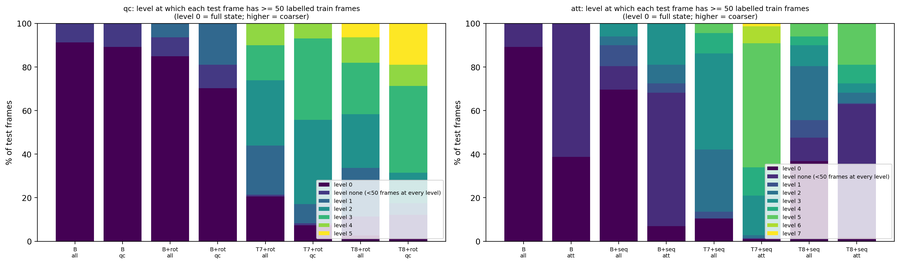

In [7]:
# Step 1b: how much of the data each back-off level resolves.
rows = []
for target in TARGETS:
    ytr = DATA["train"][f"y_{target}"]
    yte = DATA["test"][f"y_{target}"]
    for key, kind in METHODS[target].items():
        if kind != "discrete":
            continue
        ctr, cte = codes_for(DATA["train"], target, key), codes_for(DATA["test"], target, key)
        _a, _b, used = TS.backoff_scores(ctr, ytr, cte, PRIOR_FRAMES)
        ok = yte >= 0
        for lvl in range(len(ctr) + 1):
            rows.append({"target": target, "method": key, "level": lvl if lvl < len(ctr) else "none (<50 frames at every level)",
                         "variables": " ".join(LEVELS[target][key][lvl]) if lvl < len(ctr) else "",
                         "test frames %": 100 * float((used[ok] == lvl).mean()),
                         "test positive frames %": 100 * float((used[ok & (yte == 1)] == lvl).mean()),
                         "states seen in train": len(np.unique(ctr[lvl][ctr[lvl] >= 0])) if lvl < len(ctr) else np.nan})
COVER = pd.DataFrame(rows)
L.save_csv(COVER, "01b", "backoff_coverage", "all", "base", "test")
print(COVER.drop(columns="variables").round(1).to_string(index=False))
fig, axes = plt.subplots(1, len(TARGETS), figsize=(8 * len(TARGETS), 4.8), squeeze=False)
for ax, target in zip(axes[0], TARGETS):
    c = COVER[COVER.target == target]
    meths = list(dict.fromkeys(c.method))
    levels = list(dict.fromkeys(c.level))
    bottom = np.zeros(2 * len(meths))
    cmap = plt.get_cmap("viridis", len(levels))
    for li, lvl in enumerate(levels):
        vals = []
        for mth in meths:
            r = c[(c.method == mth) & (c.level == lvl)]
            vals += [float(r["test frames %"].iloc[0]) if len(r) else 0.0, float(r["test positive frames %"].iloc[0]) if len(r) else 0.0]
        vals = np.nan_to_num(np.array(vals))
        ax.bar(np.arange(len(vals)), vals, bottom=bottom, color=cmap(li), label=f"level {lvl}")
        bottom += vals
    ax.set_xticks(np.arange(2 * len(meths)), [f"{m}\n{w}" for m in meths for w in ("all", target)], fontsize=7)
    ax.set_ylabel("% of test frames")
    ax.set_title(f"{target}: level at which each test frame has >= {PRIOR_FRAMES:.0f} labelled train frames\n"
                 "(level 0 = full state; higher = coarser)", fontsize=9)
    ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
show(L.save_fig(fig, "01b", "backoff_coverage", "all", "base", "test"))

## Step 2 — 连续方法：类别权重的选择（训练集留一录像）

G8 的类别权重（不加权 / 平衡）按训练集 4 个录像的留一录像平均 AP 选。选中那一种的交叉预测分数直接用于 Step 3 的阈值。

In [8]:
# Step 2: class weight of the continuous model, chosen by LOEO AP on train.
G = {}
rows = []
for target in TARGETS:
    Dtr = DATA["train"]
    ytr = Dtr[f"y_{target}"]
    Xtr, names = g_matrix(Dtr, target)
    cvs = {}
    for cw in G_CLASS_WEIGHTS:
        t0 = time.time()
        cvs[cw] = cv_scores(g_fit_apply(Xtr, ytr, Dtr["valid"], cw))
        aps = loeo_ap(target, cvs[cw])
        rows.append({"target": target, "class_weight": str(cw), **{exp_short(e): a for e, a in zip(TRAIN_EXPERIMENTS, aps)},
                     "mean_LOEO_AP": float(np.nanmean(aps)), "seconds": time.time() - t0})
        print(f"[{target}] class_weight {cw}: LOEO AP {np.round(aps, 3)} mean {np.nanmean(aps):.3f} "
              f"({time.time() - t0:.0f} s)", flush=True)
    best = max((r for r in rows if r["target"] == target), key=lambda r: r["mean_LOEO_AP"])
    cw = None if best["class_weight"] == "None" else best["class_weight"]
    G[target] = {"class_weight": cw, "cv": cvs[cw], "names": names}
CW_TAB = pd.DataFrame(rows)
L.save_csv(CW_TAB, "02", "class_weight_choice", "all", "base", "train")
print(CW_TAB.round(3).to_string(index=False))
L.update_params("chosen", {"class_weight": {t: str(G[t]["class_weight"]) for t in TARGETS}})

[qc] class_weight None: LOEO AP [0.538 0.501 0.197 0.22 ] mean 0.364 (69 s)


[qc] class_weight balanced: LOEO AP [0.525 0.513 0.185 0.209] mean 0.358 (74 s)


[att] class_weight None: LOEO AP [0.33  0.225 0.626 0.419] mean 0.400 (95 s)


[att] class_weight balanced: LOEO AP [0.35  0.232 0.624 0.433] mean 0.410 (78 s)


  csv data/02_class_weight_choice__all__base__train.csv  rows 4
target class_weight  K_1_1  K_1_2  P_1_1  P_1_2  mean_LOEO_AP  seconds
    qc         None  0.538  0.501  0.197  0.220         0.364   69.445
    qc     balanced  0.525  0.513  0.185  0.209         0.358   73.923
   att         None  0.330  0.225  0.626  0.419         0.400   94.841
   att     balanced  0.350  0.232  0.624  0.433         0.410   78.471


{'parameters': {'RUN_NAME': '20261110_trio_focalB_v8',
  'SOURCE_RUN': '20261108_pair_state6d_clean_sw11_v3b',
  'OUTPUT_ROOT': None,
  'TRAIN_EXPERIMENTS': ['20251225_K_1_1_FCMC',
   '20251225_K_1_2_FCMC',
   '20260112_P_1_1_FCMC',
   '20260113_P_1_2_FCMC'],
  'TEST_EXPERIMENTS': ['20251225_K_1_3_FCMC',
   '20260112_P_1_3_FCMC',
   '20251220_E_1_1_FCMC',
   '20251220_E_1_2_FCMC',
   '20251220_E_1_3_FCMC'],
  'REVIEW_MIN_WATCHED_PCT': 99.0,
  'TARGETS': ['qc', 'att'],
  'DPI': 200,
  'THUMB_WIDTH': 900,
  'LABEL_CLASSES': {'wrap': ['wrap'],
   'qc': ['quick circle', 'incomplete qc', 'courtship'],
   'att': ['attack', 'attempted att', 'dash']},
  'COPIES': [['M1', 'M2'], ['M2', 'M1']],
  'EVAL_COPIES': {'qc': [0, 1], 'att': [0]},
  'D_EDGES': [0, 10, 20, 40, inf],
  'DZ_EDGES': [-inf, -20, 20, inf],
  'SP_EDGES': [0, 60, inf],
  'MD_EDGES': [0, 15, 40, inf],
  'TRIO_SPECS': {'fD': ['lin', [0, 10, 20, 40, inf]],
   'fdz': ['lin', [-inf, -20, 20, inf]],
   'fthF': ['half4', None],
   'fth

## Step 3 — 拟合全部方法、在测试集上评估

每个目标、每个方法：在全部训练集上拟合（用于测试集）；训练集交叉预测分数 → 平滑 → 阈值（F1 最大；误报 / 配对·分钟 = 0.25、0.5、1）→ 测试集固定使用。

**表**（`data/03_results__<target>`）：每个测试录像、每个方法的 AP、帧精确率、帧召回率、检出 bout / bout、误报区间 / 配对·分钟；`@FA0.25` 等列 = 训练集定到该误报率的阈值下的同样指标。

In [9]:
# Step 3: fit every method on train, evaluate on test.
for target in TARGETS:
    Dtr, Dte = DATA["train"], DATA["test"]
    ytr = Dtr[f"y_{target}"]
    m_tr = eval_mask(Dtr, target)
    mins_tr = minutes_of(Dtr, m_tr & (ytr >= 0))
    rows, S_TE, FIT = [], {}, {}
    for key, kind in METHODS[target].items():
        t0 = time.time()
        if kind == "continuous":
            Xtr, _n = g_matrix(Dtr, target)
            Xte, _n = g_matrix(Dte, target)
            cw = G[target]["class_weight"]
            fit_rows = (ytr >= 0) & Dtr["valid"]
            mdl = g_model(cw).fit(Xtr[fit_rows], ytr[fit_rows])
            base = float(ytr[fit_rows].mean())
            s_te = np.where(Dte["valid"], mdl.predict_proba(Xte)[:, 1], base)
            s_in = np.where(Dtr["valid"], mdl.predict_proba(Xtr)[:, 1], base)
            cv = G[target]["cv"]
            G[target].update({"model": mdl, "Xte": Xte})
            extra = f"gradient boosting, class_weight {cw}, {Xtr.shape[1]} columns"
        else:
            ctr, cte = codes_for(Dtr, target, key), codes_for(Dte, target, key)
            s_in, s_te, _used = TS.backoff_scores(ctr, ytr, cte, PRIOR_FRAMES)
            cv = cv_scores(backoff_fit_apply(ctr, ytr))
            extra = f"{len(ctr)} levels"
        # thresholds from cross-fitted train scores (each training video scored by a fit on the others)
        sm_tr, sm_te = smooth(Dtr, cv, target), smooth(Dte, s_te, target)
        thr, f1 = P4.best_f1_threshold(sm_tr[m_tr], ytr[m_tr])
        thr_in, f1_in = P4.best_f1_threshold(smooth(Dtr, s_in, target)[m_tr], ytr[m_tr])
        curve_tr = TS.alarm_curve(sm_tr[m_tr], ytr[m_tr], Dtr["block"][m_tr], mins_tr, y_bout=Dtr[f"yb_{target}"][m_tr])
        thr_fa = {fa: TS.threshold_from_curve(curve_tr, fa) for fa in FA_TARGETS}
        S_TE[key] = sm_te
        FIT[key] = {"threshold": thr, "f1_train": f1, "thr_fa": thr_fa, "threshold_insample": thr_in, "f1_insample": f1_in}
        rows += evaluate(target, key, sm_te, thr, thr_fa, thr_in)
        print(f"[{target}] {key}: {extra}; cross-fitted train F1 {f1:.3f}, threshold {thr:.4f}; "
              f"in-sample train F1 {f1_in:.3f} ({time.time() - t0:.0f} s)", flush=True)
    res = pd.DataFrame(rows)
    RESULTS[target] = {"table": res, "scores": S_TE, "fit": FIT}
    L.save_csv(res, "03", "results", target, "base", "test")
    show_cols = ["video", "method", "AP", "pos_rate", "precision", "recall", "bouts_found", "bouts", "false_alarms_per_min"]
    print(f"\n{target}: train-F1 threshold")
    print(res[show_cols].round(3).to_string(index=False))
    for fa in FA_TARGETS:
        cols = ["video", "method", f"bouts_found@FA{fa}", f"bouts@FA{fa}", f"false_alarms_per_min@FA{fa}"]
        print(f"\n{target}: threshold set on train to {fa} false alarms / pair-min")
        print(res[cols].round(3).to_string(index=False))

[qc] B: 1 levels; cross-fitted train F1 0.401, threshold 0.1250; in-sample train F1 0.624 (19 s)


[qc] B+rot: 2 levels; cross-fitted train F1 0.418, threshold 0.1610; in-sample train F1 0.718 (20 s)


[qc] T7+rot: 5 levels; cross-fitted train F1 0.403, threshold 0.1989; in-sample train F1 0.916 (28 s)


[qc] T8+rot: 6 levels; cross-fitted train F1 0.410, threshold 0.1845; in-sample train F1 0.940 (30 s)


[qc] G8+rot: gradient boosting, class_weight None, 21 columns; cross-fitted train F1 0.479, threshold 0.1720; in-sample train F1 0.953 (71 s)


  csv data/03_results__qc__base__test.csv  rows 25

qc: train-F1 threshold
video method    AP  pos_rate  precision  recall  bouts_found  bouts  false_alarms_per_min
K_1_3      B 0.514     0.020      0.332   0.576           31     48                 1.740
P_1_3      B 0.494     0.014      0.428   0.534           11     18                 0.732
E_1_1      B 0.027     0.002      0.038   0.220            1      4                 0.959
E_1_2      B 0.022     0.002      0.042   0.113            0      5                 0.756
E_1_3      B 0.219     0.004      0.194   0.459            5     11                 0.911
K_1_3  B+rot 0.520     0.020      0.398   0.555           28     48                 1.340
P_1_3  B+rot 0.525     0.014      0.538   0.495           10     18                 0.537
E_1_1  B+rot 0.030     0.002      0.046   0.207            0      4                 0.623
E_1_2  B+rot 0.029     0.002      0.052   0.084            0      5                 0.519
E_1_3  B+rot 0.245     0.

... (2 outputs left out)

[att] T7+seq: 8 levels; cross-fitted train F1 0.385, threshold 0.1974; in-sample train F1 0.763 (23 s)


[att] T8+seq: 6 levels; cross-fitted train F1 0.155, threshold 0.0456; in-sample train F1 0.816 (20 s)


[att] G8+seq: gradient boosting, class_weight balanced, 17 columns; cross-fitted train F1 0.434, threshold 0.8309; in-sample train F1 0.903 (51 s)


  csv data/03_results__att__base__test.csv  rows 25

att: train-F1 threshold
video method    AP  pos_rate  precision  recall  bouts_found  bouts  false_alarms_per_min
K_1_3      B 0.020     0.000      0.023   0.611            8     10                11.847
P_1_3      B 0.280     0.002      0.226   0.563           20     35                 3.462
E_1_1      B   NaN     0.000      0.000   0.000            0      0                 6.815
E_1_2      B 0.018     0.001      0.032   0.151            1      8                 6.341
E_1_3      B 0.021     0.000      0.020   0.395            3      7                 6.903
K_1_3  B+seq 0.038     0.000      0.045   0.523            8     10                 6.681
P_1_3  B+seq 0.350     0.002      0.364   0.453           14     35                 1.731
E_1_1  B+seq   NaN     0.000      0.000   0.000            0      0                 2.925
E_1_2  B+seq 0.023     0.001      0.066   0.127            1      8                 3.443
E_1_3  B+seq 0.031     

## Step 4 — 图：主表、PR 曲线、相同误报率下的 bout 检出

- **`04_main_table__<target>`**：每个指标一个面板（训练集 F1 阈值），每个测试录像一组柱子。AP 面板的虚线 = 随机水平（正例帧比例）。
- **`04_pr__<target>`**：每个测试录像的精确率–召回率曲线，圆点 = 训练集阈值。
- **`04_bouts_vs_fa__<target>`**：阈值从高到低扫一遍：横轴误报 / 配对·分钟，纵轴检出 bout 数；三角 = 训练集定到 0.25 / 0.5 / 1 误报的阈值在测试集上的位置。

  fig figures/04_main_table__qc__base__test.png


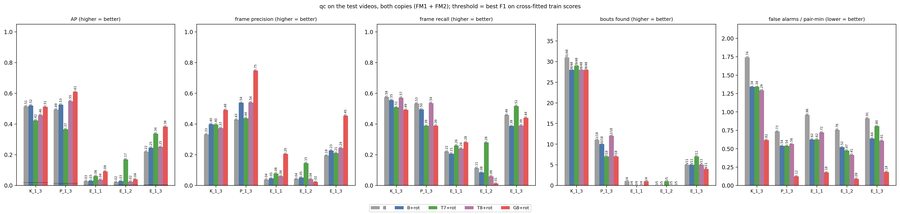

  fig figures/04_pr__qc__base__test.png


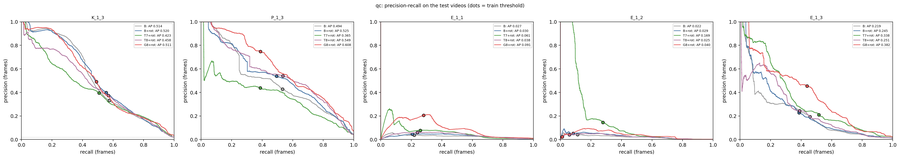

  fig figures/04_bouts_vs_fa__qc__base__test.png


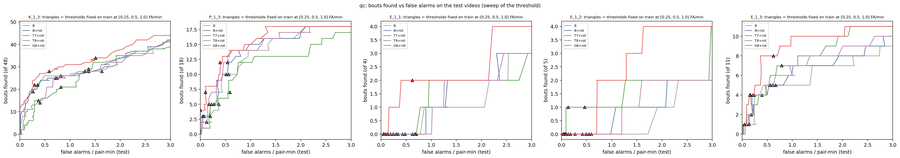

  csv data/04_bouts_vs_fa__qc__base__test.csv  rows 7491


  fig figures/04_main_table__att__base__test.png


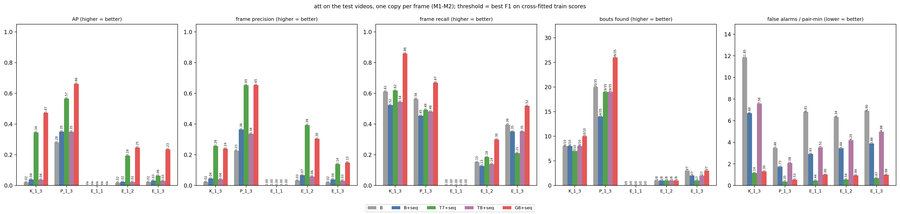

  fig figures/04_pr__att__base__test.png


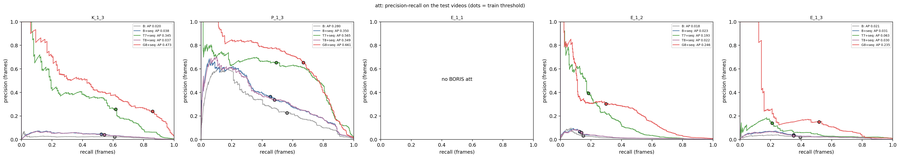

  fig figures/04_bouts_vs_fa__att__base__test.png


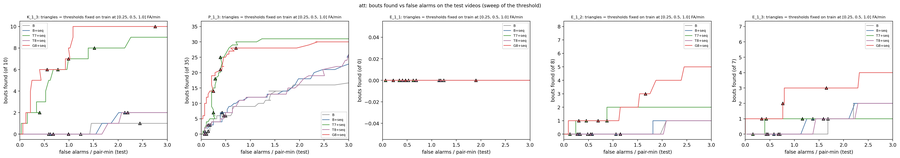

  csv data/04_bouts_vs_fa__att__base__test.csv  rows 6795


In [10]:
# Step 4: figures.
MAIN_METRICS = [("AP", "AP (higher = better)"), ("precision", "frame precision (higher = better)"),
                ("recall", "frame recall (higher = better)"), ("bouts_found", "bouts found (higher = better)"),
                ("false_alarms_per_min", "false alarms / pair-min (lower = better)")]
for target in TARGETS:
    res = RESULTS[target]["table"]
    meths = list(METHODS[target])
    vids = list(dict.fromkeys(res.video))
    fig, axes = plt.subplots(1, len(MAIN_METRICS), figsize=(4.6 * len(MAIN_METRICS), 5.4))
    w = 0.8 / len(meths)
    for ax, (col, nm) in zip(axes, MAIN_METRICS):
        for mi, key in enumerate(meths):
            vals = [float(res[(res.video == v) & (res.method == key)][col].iloc[0]) for v in vids]
            x = np.arange(len(vids)) + (mi - (len(meths) - 1) / 2) * w
            ax.bar(x, np.nan_to_num(vals), width=w, color=METHOD_COLOR[key], label=key)
            for xi, v, vid in zip(x, vals, vids):
                if col == "bouts_found":
                    txt = f"{int(v)}/{int(res[(res.video == vid) & (res.method == key)]['bouts'].iloc[0])}"
                else:
                    txt = f"{v:.2f}" if np.isfinite(v) else "n/a"
                ax.text(xi, np.nan_to_num(v), txt, ha="center", va="bottom", fontsize=5.5, rotation=90)
        if col == "AP":
            for vi, v in enumerate(vids):
                ax.hlines(float(res[res.video == v]["pos_rate"].iloc[0]), vi - 0.4, vi + 0.4, color="k", ls=":", lw=1)
        if col in ("AP", "precision", "recall"):
            ax.set_ylim(0, 1.05)
        else:
            ax.set_ylim(0, max(ax.get_ylim()[1], 1) * 1.2)
        ax.set_xticks(np.arange(len(vids)), vids, fontsize=8)
        ax.set_title(nm, fontsize=9)
    h, lab = axes[0].get_legend_handles_labels()
    fig.legend(h, lab, loc="lower center", ncol=len(meths), fontsize=8)
    ev = "both copies (FM1 + FM2)" if target == "qc" else "one copy per frame (M1-M2)"
    fig.suptitle(f"{target} on the test videos, {ev}; threshold = best F1 on cross-fitted train scores", fontsize=10)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    show(L.save_fig(fig, "04", "main_table", target, "base", "test"))

    D = DATA["test"]
    y = D[f"y_{target}"]
    fig, axes = plt.subplots(1, len(vids), figsize=(5.2 * len(vids), 4.6), squeeze=False)
    fig2, axes2 = plt.subplots(1, len(vids), figsize=(5.2 * len(vids), 4.6), squeeze=False)
    curves = []
    for ax, ax2, (ei, e) in zip(axes[0], axes2[0], enumerate(D["exp_names"])):
        m = (D["exp"] == ei) & eval_mask(D, target)
        yy, bb, yb = y[m], D["block"][m], D[f"yb_{target}"][m]
        mins = minutes_of(D, m & (y >= 0))
        for key in meths:
            ss = RESULTS[target]["scores"][key][m]
            r = res[(res.video == exp_short(e)) & (res.method == key)].iloc[0]
            if (yy == 1).any():
                ok = yy >= 0
                p_, r_, _t = precision_recall_curve(yy[ok], ss[ok])
                ax.plot(r_, p_, color=METHOD_COLOR[key], lw=1.3, label=f"{key}: AP {r.AP:.3f}")
                ax.plot(r.recall, r.precision, "o", color=METHOD_COLOR[key], mec="k", ms=6)
            c = TS.alarm_curve(ss, yy, bb, mins, y_bout=yb)
            c["video"], c["method"] = exp_short(e), key
            curves.append(c)
            ax2.plot(c.false_alarms_per_min, c.bouts_found, color=METHOD_COLOR[key], lw=1.3, label=key)
            for fa in FA_TARGETS:
                ax2.plot(r[f"false_alarms_per_min@FA{fa}"], r[f"bouts_found@FA{fa}"], "^", color=METHOD_COLOR[key], mec="k", ms=6)
        n_b = int(res[res.video == exp_short(e)]["bouts"].iloc[0])
        if (yy == 1).any():
            ax.axhline(float((yy[yy >= 0] == 1).mean()), color="0.7", ls=":", lw=1)
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1)
            ax.legend(fontsize=6.5, loc="upper right")
        else:
            ax.text(0.5, 0.5, f"no BORIS {target}", ha="center", transform=ax.transAxes)
        ax.set_xlabel("recall (frames)")
        ax.set_ylabel("precision (frames)")
        ax.set_title(f"{exp_short(e)}", fontsize=9)
        ax2.set_xlim(0, 3)
        ax2.set_xlabel("false alarms / pair-min (test)")
        ax2.set_ylabel(f"bouts found (of {n_b})")
        ax2.set_title(f"{exp_short(e)}: triangles = thresholds fixed on train at {FA_TARGETS} FA/min", fontsize=8)
        ax2.legend(fontsize=7)
    fig.suptitle(f"{target}: precision-recall on the test videos (dots = train threshold)", fontsize=10)
    fig.tight_layout()
    show(L.save_fig(fig, "04", "pr", target, "base", "test"))
    fig2.suptitle(f"{target}: bouts found vs false alarms on the test videos (sweep of the threshold)", fontsize=10)
    fig2.tight_layout()
    show(L.save_fig(fig2, "04", "bouts_vs_fa", target, "base", "test"))
    L.save_csv(pd.concat(curves, ignore_index=True), "04", "bouts_vs_fa", target, "base", "test")

## Step 5 — 连续模型（G8）的解释：哪些变量重要、怎样影响

- **置换重要性**（`05_importance__<target>`）：在测试集上（全部正例帧 + 随机 30 万负例帧，评估副本），把一个变量（连同它的 cos 列）随机打乱，看帧级 AP（未平滑的模型输出）下降多少，重复 3 次取平均。下降越多 = 模型越依赖这个变量。
- **部分依赖**（`05_partial_dependence__<target>`）：最重要的 6 个变量，把该变量在 2 万个随机训练帧上统一设成某个值（角度的 cos 列一起改），其余变量保持实际值，画出模型平均输出随该值变化的曲线。这相当于离散方法里"这个变量的不同档，比例有多高"。

  csv data/05_importance__qc__base__test.csv  rows 15

qc (G8+rot): frame AP on the sample 0.708; drop when a variable is shuffled
target variable  AP_drop_mean  AP_drop_sd  AP_full
    qc       fD        0.4194      0.0034   0.7078
    qc      fdz        0.2456      0.0031   0.7078
    qc     fthF        0.1087      0.0015   0.7078
    qc      Fsp        0.0637      0.0011   0.7078
    qc      rdz        0.0469      0.0006   0.7078
    qc      fsp        0.0451      0.0007   0.7078
    qc       rD        0.0415      0.0017   0.7078
    qc      rot        0.0313      0.0004   0.7078
    qc     fthM        0.0298      0.0006   0.7078
    qc       mD        0.0260      0.0002   0.7078
    qc     mthf        0.0138      0.0002   0.7078
    qc     rthF        0.0136      0.0009   0.7078
    qc     rthM        0.0036      0.0005   0.7078
    qc      rsp        0.0032      0.0007   0.7078
    qc     mthr       -0.0012      0.0001   0.7078


  fig figures/05_importance__qc__base__test.png


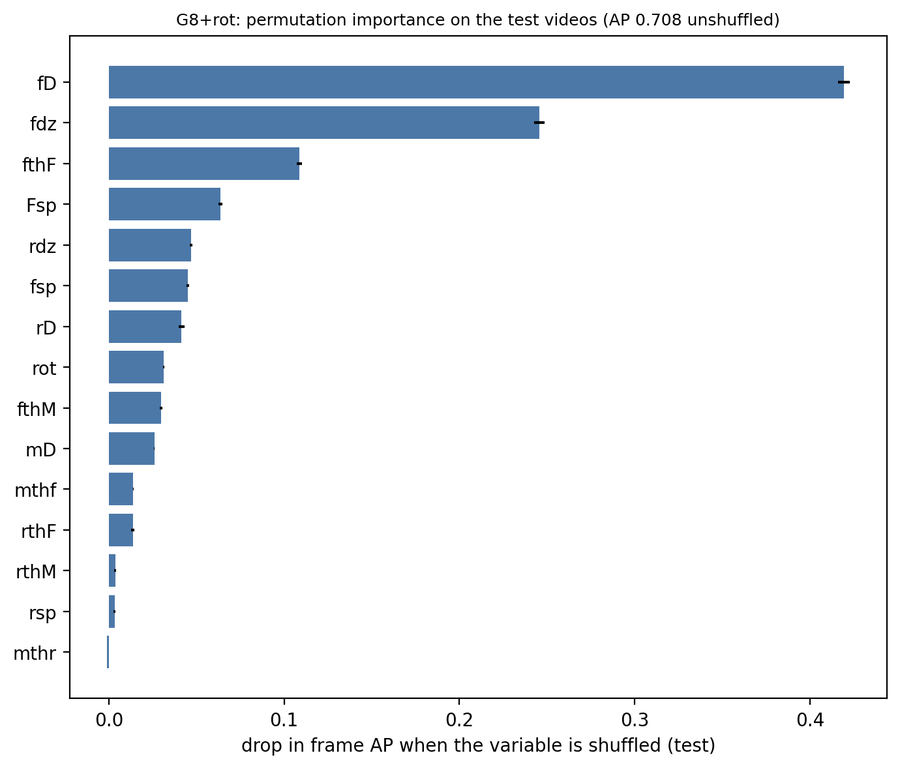

  fig figures/05_partial_dependence__qc__base__train.png


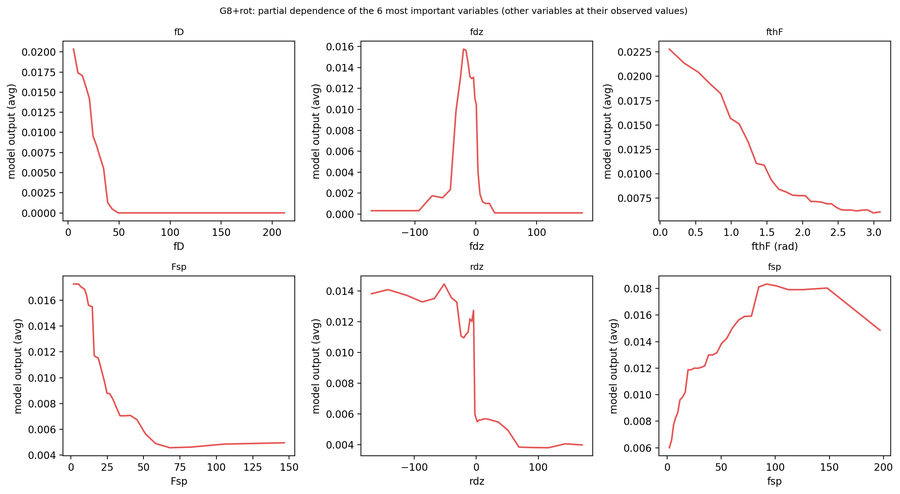

  csv data/05_importance__att__base__test.csv  rows 15

att (G8+seq): frame AP on the sample 0.599; drop when a variable is shuffled
target variable  AP_drop_mean  AP_drop_sd  AP_full
   att     dmin        0.5357      0.0021   0.5991
   att     turn        0.2375      0.0087   0.5991
   att      fsp        0.1708      0.0051   0.5991
   att      rsp        0.0972      0.0064   0.5991
   att     mDxy        0.0884      0.0074   0.5991
   att      who        0.0788      0.0017   0.5991
   att     lead        0.0579      0.0024   0.5991
   att      mdz        0.0373      0.0011   0.5991
   att     tmin        0.0235      0.0026   0.5991
   att     mthr        0.0208      0.0008   0.5991
   att       fD        0.0185      0.0006   0.5991
   att      Fsp        0.0163      0.0009   0.5991
   att     mthf        0.0036      0.0003   0.5991
   att       rD        0.0023      0.0033   0.5991
   att      dsp       -0.0078      0.0012   0.5991


  fig figures/05_importance__att__base__test.png


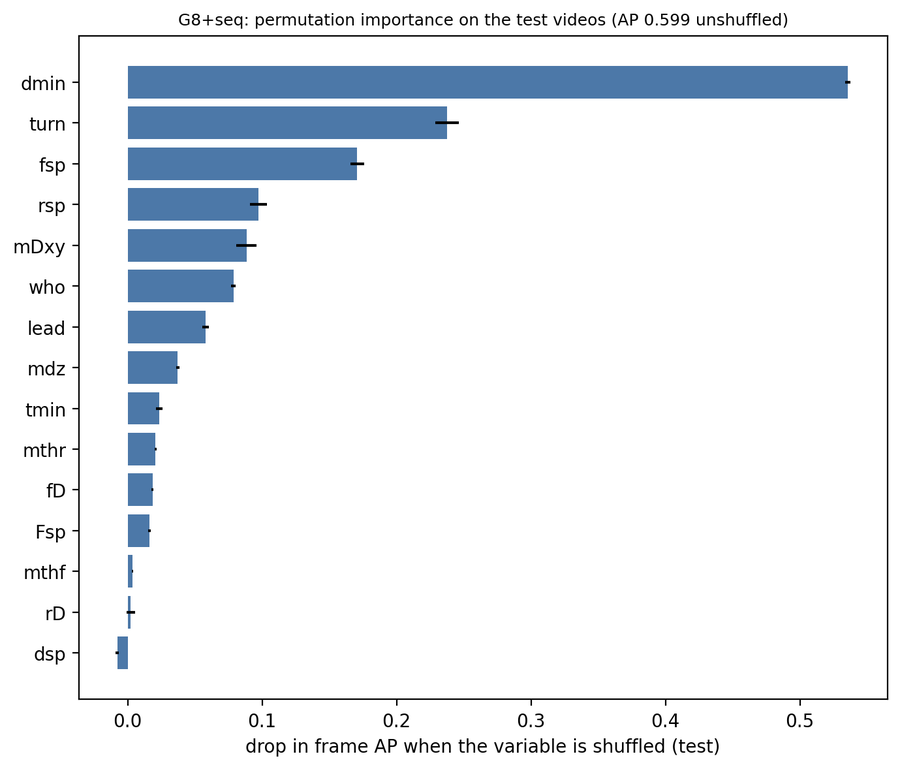

  fig figures/05_partial_dependence__att__base__train.png


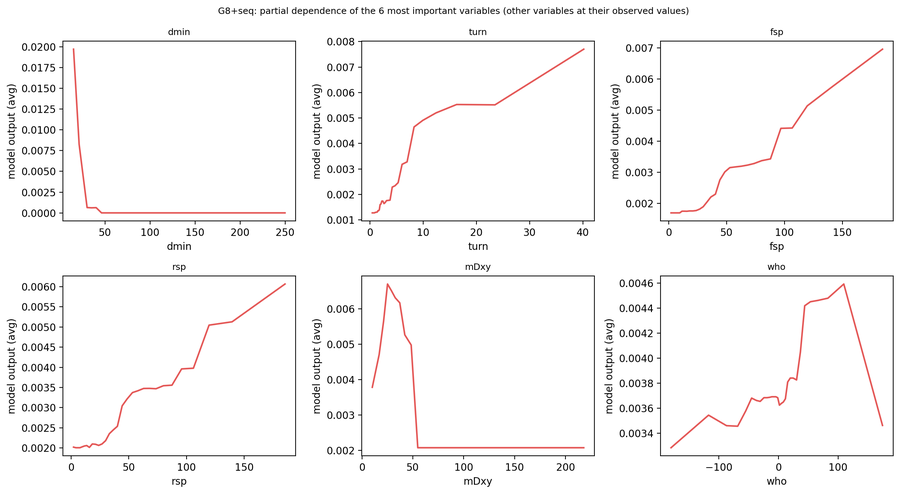

In [11]:
# Step 5: permutation importance on test and partial dependence of the continuous models.
rng = np.random.default_rng(0)
for target in TARGETS:
    key = [k for k, v in METHODS[target].items() if v == "continuous"][0]
    mdl, Xte, names = G[target]["model"], G[target]["Xte"], G[target]["names"]
    D = DATA["test"]
    y = D[f"y_{target}"]
    m = eval_mask(D, target) & (y >= 0) & D["valid"]
    pos, neg = np.flatnonzero(m & (y == 1)), np.flatnonzero(m & (y == 0))
    idx = np.concatenate([pos, rng.choice(neg, min(IMPORTANCE_NEG_SAMPLE, len(neg)), replace=False)])
    X, yy = Xte[idx], y[idx]
    base_ap = average_precision_score(yy, mdl.predict_proba(X)[:, 1])
    rows = []
    for v in G_FEATURES[target]:
        cols = [i for i, n in enumerate(names) if n in (v, f"cos_{v}")]
        drops = []
        for _r in range(IMPORTANCE_REPEATS):
            Xp = X.copy()
            perm = rng.permutation(len(Xp))
            Xp[:, cols] = Xp[perm][:, cols]
            drops.append(base_ap - average_precision_score(yy, mdl.predict_proba(Xp)[:, 1]))
        rows.append({"target": target, "variable": v, "AP_drop_mean": float(np.mean(drops)), "AP_drop_sd": float(np.std(drops))})
    IMP = pd.DataFrame(rows).sort_values("AP_drop_mean", ascending=False)
    IMP["AP_full"] = base_ap
    L.save_csv(IMP, "05", "importance", target, "base", "test")
    print(f"\n{target} ({key}): frame AP on the sample {base_ap:.3f}; drop when a variable is shuffled")
    print(IMP.round(4).to_string(index=False))
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(IMP) + 1.2))
    ax.barh(IMP.variable[::-1], IMP.AP_drop_mean[::-1], xerr=IMP.AP_drop_sd[::-1], color="#4C78A8")
    ax.set_xlabel("drop in frame AP when the variable is shuffled (test)")
    ax.set_title(f"{key}: permutation importance on the test videos (AP {base_ap:.3f} unshuffled)", fontsize=9)
    fig.tight_layout()
    show(L.save_fig(fig, "05", "importance", target, "base", "test"))

    Xtr, _n = g_matrix(DATA["train"], target)
    ok = np.flatnonzero(DATA["train"]["valid"] & (DATA["train"][f"y_{target}"] >= 0))
    Xs = Xtr[rng.choice(ok, min(PDP_SAMPLE, len(ok)), replace=False)]
    top = list(IMP.variable[:PDP_TOP])
    fig, axes = plt.subplots(2, (len(top) + 1) // 2, figsize=(4.2 * ((len(top) + 1) // 2), 7), squeeze=False)
    for ax, v in zip(axes.ravel(), top):
        j = names.index(v)
        jc = names.index(f"cos_{v}") if f"cos_{v}" in names else None
        grid = np.unique(np.nanpercentile(Xs[:, j], np.linspace(2, 98, 30)))
        avg = []
        for g in grid:
            Xc = Xs.copy()
            Xc[:, j] = g
            if jc is not None:
                Xc[:, jc] = np.cos(g)
            avg.append(float(mdl.predict_proba(Xc)[:, 1].mean()))
        ax.plot(grid, avg, color="#E45756", lw=1.6)
        ax.set_xlabel(v + (" (rad)" if v in ANGLES else ""))
        ax.set_ylabel("model output (avg)")
        ax.set_title(v, fontsize=9)
    for ax in axes.ravel()[len(top):]:
        ax.axis("off")
    fig.suptitle(f"{key}: partial dependence of the {len(top)} most important variables "
                 "(other variables at their observed values)", fontsize=9)
    fig.tight_layout()
    show(L.save_fig(fig, "05", "partial_dependence", target, "base", "train"))

## Step 6 — 汇总

每个目标：所有测试录像合起来（bout 和误报区间相加），F1 阈值和三个固定误报率阈值下各方法检出的 bout；平均 AP（有正例的录像）。再列出输出文件。

In [12]:
# Step 6: totals over the test videos and the file list.
for target in TARGETS:
    res = RESULTS[target]["table"]
    agg = {"bouts": "sum", "bouts_found": "sum", "false_alarm_intervals": "sum", "pair_minutes": "sum"}
    for fa in FA_TARGETS:
        agg.update({f"bouts_found@FA{fa}": "sum", f"false_alarm_intervals@FA{fa}": "sum"})
    tot = res.groupby("method", sort=False).agg(agg).reset_index()
    tot["false_alarms_per_min"] = tot.false_alarm_intervals / tot.pair_minutes
    for fa in FA_TARGETS:
        tot[f"false_alarms_per_min@FA{fa}"] = tot[f"false_alarm_intervals@FA{fa}"] / tot.pair_minutes
    tot["mean_AP_over_videos_with_positives"] = res.groupby("method", sort=False)["AP"].mean().to_numpy()
    L.save_csv(tot, "06", "totals", target, "base", "test")
    print(f"\n{target}, all test videos together ({', '.join(dict.fromkeys(res.video))}):")
    print(tot.round(3).to_string(index=False))
    piv = res.pivot(index="method", columns="video", values="AP").loc[list(METHODS[target])]
    print(f"\n{target}: AP per test video")
    print(piv.round(3).to_string())
print("\nskipped test videos:", SKIPPED or "none")
print("\nfiles:")
for p in sorted(L.root.rglob("*")):
    if p.is_file() and "thumbs" not in p.parts:
        print(" ", p.relative_to(L.root))

  csv data/06_totals__qc__base__test.csv  rows 5

qc, all test videos together (K_1_3, P_1_3, E_1_1, E_1_2, E_1_3):
method  bouts  bouts_found  false_alarm_intervals  pair_minutes  bouts_found@FA0.25  false_alarm_intervals@FA0.25  bouts_found@FA0.5  false_alarm_intervals@FA0.5  bouts_found@FA1.0  false_alarm_intervals@FA1.0  false_alarms_per_min  false_alarms_per_min@FA0.25  false_alarms_per_min@FA0.5  false_alarms_per_min@FA1.0  mean_AP_over_videos_with_positives
     B     86           48                    314       301.862                  23                            44                 35                          129                 43                          253                 1.040                        0.146                       0.427                       0.838                               0.255
 B+rot     86           43                    225       301.862                  26                            53                 34                          111                 